**Part 0**

In [5]:
# import libraries
import numpy as np
from scipy import stats
from sklearn.linear_model import LinearRegression
import pandas as pd
import matplotlib.pyplot as plt

In [6]:
# linear regression function
def fit_linear_regression(x,y):
    # slope and intercept
    beta1 = stats.pearsonr(x,y)[0] * np.std(y) / np.std(x)
    beta0 = np.mean(y) - beta1 * np.mean(x)
    return beta0, beta1

# generate sample data
np.random.seed(42)
x_sim = np.random.normal(0,1,100)
y_sim = 2 + 3 * x_sim + np.random.normal(0,1,100)

# run function
b0, b1 = fit_linear_regression(x_sim, y_sim)

# prewritten function
model = LinearRegression().fit(x_sim.reshape(-1,1), y_sim)

# print
print(f"Custom function: beta0 = {b0:.4f}, beta1 = {b1:.4f}")
print(f"Prewritten function: beta0 = {model.intercept_:.4f}, beta1 = {model.coef_[0]:.4f}")

Custom function: beta0 = 2.0074, beta1 = 2.8567
Prewritten function: beta0 = 2.0074, beta1 = 2.8567


**Part 1**

Left to Right: beta0 = -13875.9448, beta1 = 1.0442
Right to Left: beta0 = 17150.4310, beta1 = 0.9501


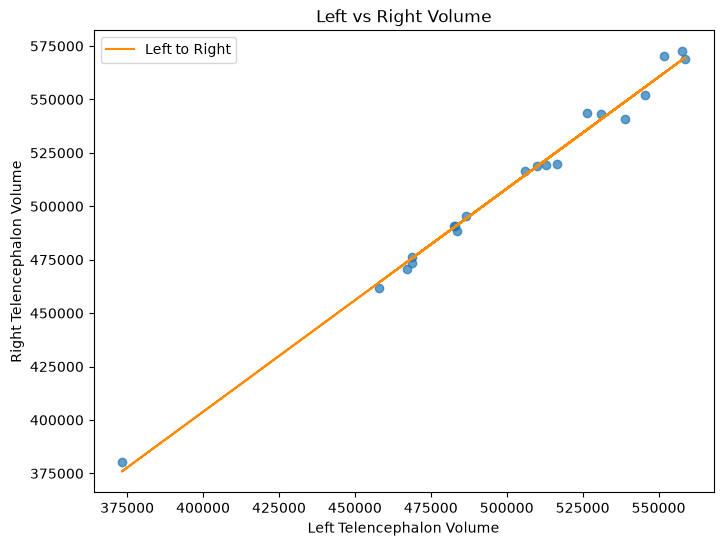

In [15]:
# load the dataset
from matplotlib.pyplot import plot


url = "https://raw.githubusercontent.com/smart-stats/ds4bio_book/refs/heads/main/qbook/assets/kirby21.csv"
kirby = pd.read_csv(url)

# get volume data 
left_tel = kirby[(kirby['roi'] == 'Telencephalon_L')]['volume'].values
right_tel = kirby[(kirby['roi'] == 'Telencephalon_R')]['volume'].values

# fit linear regression
b0_LR, b1_LR = fit_linear_regression(left_tel, right_tel)
b0_RL, b1_RL = fit_linear_regression(right_tel, left_tel)

# print
print(f"Left to Right: beta0 = {b0_LR:.4f}, beta1 = {b1_LR:.4f}")
print(f"Right to Left: beta0 = {b0_RL:.4f}, beta1 = {b1_RL:.4f}")

# make scatterplot
plt.figure(figsize=(8,6))
plt.scatter(left_tel, right_tel, alpha=0.7)

# regression line
plt.plot(left_tel, b0_LR + b1_LR * left_tel, color='darkorange', label='Left to Right')
plt.xlabel('Left Telencephalon Volume')
plt.ylabel('Right Telencephalon Volume')
plt.title('Left vs Right Volume')
plt.legend()
plt.show()




**Part 2**

The impact of replacing X with cX is that the new estimate of B is the original estimate divided by c. 

**Part 3**

In [17]:
# create simulated data
x_sim_data = np.array([0,0,0,0,0,1,1,1,1,1])
y_sim_data = np.array([2,4,6,8,10,100,110,120,130,140])

# fit the linear regression model
model_sim = LinearRegression().fit(x_sim_data.reshape(-1,1), y_sim_data)
beta0_sim = model_sim.intercept_
beta1_sim = model_sim.coef_[0]

#print results
print(f'Group 0 Mean: {np.mean(y_sim_data[x_sim_data==0]):.1f}')
print(f'Predicted Y when X = 0: {beta0_sim:.1f}')
print(f'Group 1 Mean: {np.mean(y_sim_data[x_sim_data==1]):.1f}')
print(f'Predicted Y when X = 1: {beta0_sim + beta1_sim:.1f}')

Group 0 Mean: 6.0
Predicted Y when X = 0: 6.0
Group 1 Mean: 120.0
Predicted Y when X = 1: 120.0


**Part 4**

If we divide vectors X and Y by their standard deviations, we get new scaled variables. When we divide a variable by its standard deviation, we get the new variable with a standard deviation of 1. The correlation coefficient is also invariant to linear scaling, so the correlation between the scaled and orginal is identical. The slope is equal to this correlation, which is 1. 

**Part 5**